# Splitting Orders Across AMM Pools with CVaR Execution-Risk Control

**Convex Optimization — Project 3**  ·  Parham Moshashaei (402111389)

A large sell order (ETH → USDC) can be split over several AMM pools.  Impact is quadratic in
the clip size, every extra pool costs gas, and the effective pool depth at execution time is
uncertain.  This notebook solves the convex CVaR routing problem of the project statement on
**real data** and tests it on **real trades**.

Pipeline (all code in `../src/amm_cvar`, runnable scripts in `../scripts`):

1. real data: Binance ETH/USDT aggregated trades (30 days, 25.5M trades) + DefiLlama TVL of
   5 real USDC-WETH pools (Uniswap V3 ×3 fee tiers, Uniswap V2, SushiSwap)
2. convex cost model `c_m(f) = a_m f + b_m f^2/L_m` derived from `xy = k`
3. scenario model `L_{m,k} = L_m(1-δ_{m,k})` from historical real TVL deviations
4. CVXPY solution of  `min (1/K)Σ C_k + λ·CVaR_α(C)`  (statement formulation)
5. sensitivity on α, F, δ  + baselines (single-pool best, mean-only)
6. **walk-forward backtest on 2,500 real parent orders** (no look-ahead)

See `README.md` for the full derivation, the data-provenance table and the review of the
issues fixed relative to the earlier notebooks.

## 0. Setup

In [1]:
import sys, json, warnings
from pathlib import Path
sys.path.insert(0, str(Path("..").resolve() / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from amm_cvar import config as C
from amm_cvar.scenarios import trailing_scenarios, realized_state
from amm_cvar.optimizer import solve_cvar_routing, problem_dimensions
from amm_cvar.baselines import (
    mean_only_allocation, single_pool_best_mean, single_pool_best_liquidity,
    equal_split, liquidity_proportional, evaluate_allocation,
)
from amm_cvar.metrics import empirical_var, empirical_cvar, summarize_losses
from amm_cvar.cost_model import xyk_exact_impact, quadratic_impact, fit_impact_regression

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
print("setup ok; seeds fixed at", C.SEED)

setup ok; seeds fixed at 42


## 1. Cost model from `xy = k`

Selling USD notional `n` against a constant-product pool with output-side reserve `y = TVL/2`
costs, exactly,

$$\text{cost}(n) = \frac{n^2}{y+n} \approx \frac{n^2}{y} = b\frac{n^2}{L}, \quad L := y = \tfrac{\text{TVL}}{2},\ b = 1$$

plus the linear fee `a f` with `a = φ` (protocol fee).  The quadratic surrogate is what the
project statement prescribes (and it is DCP: `quad_over_lin`).  Below: surrogate vs. exact
impact — the Taylor error is what we accept for convexity.

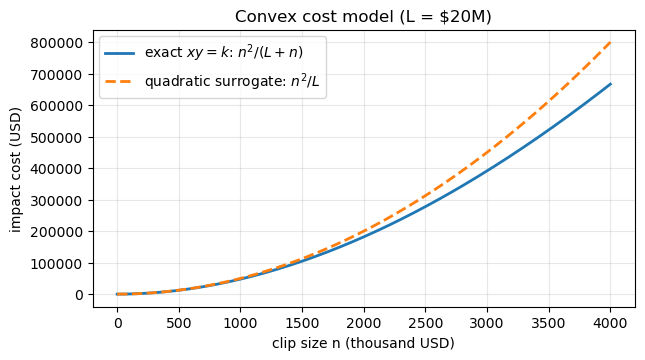

relative error at 0.1% of reserve: 0.10%
relative error at 1.0% of reserve: 1.00%
relative error at 5.0% of reserve: 5.00%


In [2]:
L_pool = 20e6          # $20M output-side reserve
n = np.linspace(0, 0.2 * L_pool, 200)
plt.figure(figsize=(7, 3.6))
plt.plot(n / 1e3, xyk_exact_impact(n, L_pool), label=r"exact $xy=k$: $n^2/(L+n)$", lw=2)
plt.plot(n / 1e3, quadratic_impact(n, L_pool), "--", label=r"quadratic surrogate: $n^2/L$", lw=2)
plt.xlabel("clip size n (thousand USD)")
plt.ylabel("impact cost (USD)")
plt.title(f"Convex cost model (L = ${L_pool/1e6:.0f}M)")
plt.legend(); plt.grid(alpha=0.3); plt.show()

for frac in (0.001, 0.01, 0.05):
    n_ = frac * L_pool
    err = abs(quadratic_impact(n_, L_pool) - xyk_exact_impact(n_, L_pool)) / xyk_exact_impact(n_, L_pool)
    print(f"relative error at {frac:.1%} of reserve: {err:.2%}")

## 2. Real data

Every quantity below is downloaded or derived from downloads — nothing is invented.  (The
earlier notebooks claimed "real Uniswap data" and "historical MEV slippage" while using
hardcoded tables and `np.random` draws; see README §6.)

In [3]:
meta = pd.read_csv(C.PROCESSED_DIR / "pools_meta.csv")
tvl = pd.read_csv(C.PROCESSED_DIR / "tvl_daily.csv", index_col=0, parse_dates=True)
tvl.index = pd.to_datetime(tvl.index, utc=True)
orders = pd.read_csv(C.PROCESSED_DIR / "parent_orders.csv")
trade_stats = json.loads((C.PROCESSED_DIR / "trade_stats.json").read_text())
impact_fit = json.loads((C.PROCESSED_DIR / "impact_fit.json").read_text())

print(f"real trades parsed:   {trade_stats['n_trades']:,}  (${trade_stats['sell_notional_usd']+trade_stats['buy_notional_usd']/1e9:.1f}B notional)")
print(f"real parent orders:   {len(orders)}   window {orders['ts'].min()[:10]} .. {orders['ts'].max()[:10]}")
print(f"order size F: median ${orders['F'].median():,.0f}, p95 ${orders['F'].quantile(0.95):,.0f}, max ${orders['F'].max():,.0f}")
print(f"real pools: {len(meta)}\n")
meta[["name", "fee", "gas_usd_raw", "tvl_current"]]

real trades parsed:   25,544,800  ($11982345581.5B notional)
real parent orders:   2500   window 2026-08-16 .. 2026-09-14
order size F: median $133,977, p95 $931,872, max $16,666,139
real pools: 5



,name,fee,gas_usd_raw,tvl_current
0,uniswap-v3 USDC-WETH (0.05%),0.00,9.13,100407599
1,uniswap-v3 USDC-WETH (0.3%),0.00,9.13,37632019
2,uniswap-v2 USDC-WETH,0.00,7.40,21146527
3,uniswap-v3 USDC-WETH (0.01%),0.00,9.13,6546328
4,sushiswap USDC-WETH,0.00,7.40,290456


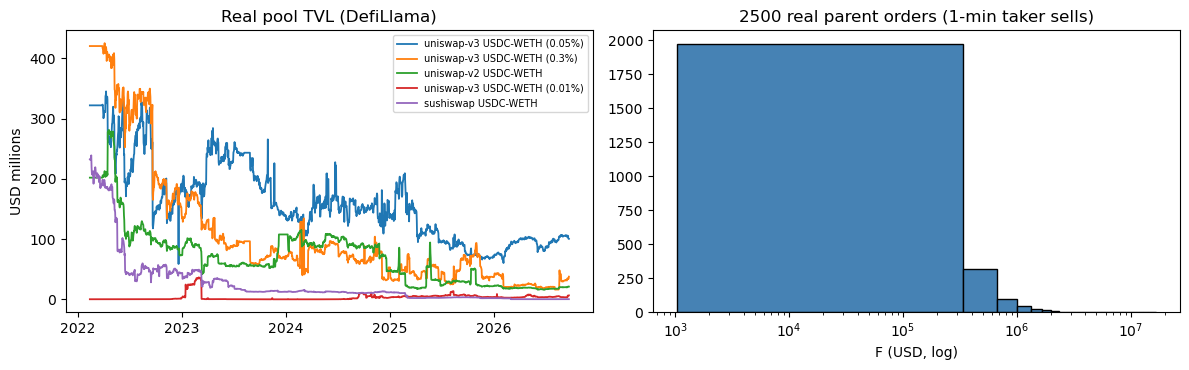

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for name in tvl.columns:
    ax[0].plot(tvl.index, tvl[name] / 1e6, label=name, lw=1.3)
ax[0].set_title("Real pool TVL (DefiLlama)")
ax[0].set_ylabel("USD millions"); ax[0].legend(fontsize=7)
ax[1].hist(orders["F"], bins=50, color="steelblue", edgecolor="black")
ax[1].set_xscale("log")
ax[1].set_title(f"{len(orders)} real parent orders (1-min taker sells)")
ax[1].set_xlabel("F (USD, log)")
plt.tight_layout(); plt.show()

In [5]:
# model fidelity on the real tape: execution cost is positive and increasing in size
print(f"bin-mean LSQ on 1s realised impacts: cost ~= {impact_fit['a_tape']:.3e} n + {impact_fit['b_tape']:.3e} n^2  (R2={impact_fit['r2']:.2f})")
print(f"cost increasing in size: {impact_fit['cost_increasing']} (rank corr {impact_fit['spearman_size_cost']:.2f})")
print(f"cost per USD: {impact_fit['bps_at_smallest_bin']:.2f} bps (small clips) -> {impact_fit['bps_at_largest_bin']:.2f} bps (large clips)")

bin-mean LSQ on 1s realised impacts: cost ~= 1.280e-04 n + -1.042e-09 n^2  (R2=0.92)
cost increasing in size: True (rank corr 0.88)
cost per USD: 0.54 bps (small clips) -> 0.71 bps (large clips)


## 3. Scenarios from real TVL deviations

$$\delta_{m,k} = \text{clip}\big(1 - L_m(d{-}k)/G_m,\ 0,\ \bar\delta\big), \qquad
G_m = \text{geometric mean of } L_m \text{ over the trailing year}$$

* adverse-only (`δ ≥ 0`), same historical day for all pools (correlation preserved)
* measured against the pool's **own typical level** so that secular trends do not invert the
  risk ordering (a collapsed pool must not look "safe")
* only days strictly before the execution date (no look-ahead)
* `K = 120`: the 24 worst shortfall days + a seeded sample of the rest

reference date: 2026-08-31   K = 120
pool                                       mean d    p95 d    max d          L_nom
uniswap-v3 USDC-WETH (0.05%)                0.062    0.192    0.292 $   53,470,826
uniswap-v3 USDC-WETH (0.3%)                 0.208    0.479    0.487 $   15,054,636
uniswap-v2 USDC-WETH                        0.098    0.241    0.251 $   10,083,282
uniswap-v3 USDC-WETH (0.01%)                0.139    0.390    0.434 $    1,825,238
sushiswap USDC-WETH                         0.310    0.600    0.600 $      137,920


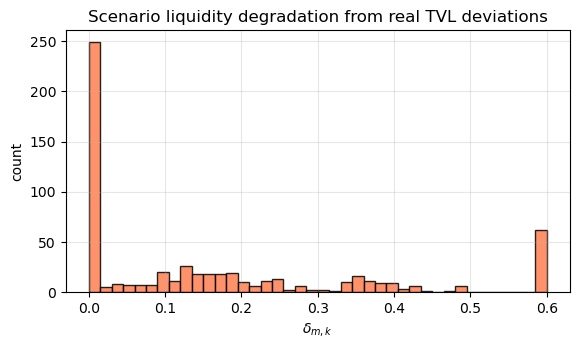

In [6]:
ref_date = pd.Timestamp(C.TRADE_START, tz="UTC") + pd.Timedelta(days=15)
scen = trailing_scenarios(tvl, ref_date)
names = list(tvl.columns)
L_scen = scen["L_scenarios"]
K = L_scen.shape[1]

print(f"reference date: {ref_date.date()}   K = {K}")
print(f"{'pool':40s} {'mean d':>8s} {'p95 d':>8s} {'max d':>8s} {'L_nom':>14s}")
for i, name in enumerate(names):
    d = scen["deltas"][i]
    print(f"{name:40s} {d.mean():8.3f} {np.quantile(d, .95):8.3f} {d.max():8.3f} ${scen['L_nominal'][i]:13,.0f}")

plt.figure(figsize=(6.5, 3.4))
plt.hist(scen["deltas"].ravel(), bins=40, color="coral", edgecolor="black", alpha=0.85)
plt.xlabel(r"$\delta_{m,k}$"); plt.ylabel("count")
plt.title("Scenario liquidity degradation from real TVL deviations")
plt.grid(alpha=0.3); plt.show()

## 4. The optimisation problem (project statement)

$$\min_{f,z,t,u} \ \frac1K\sum_k C_k(f) + \lambda\,\mathrm{CVaR}_\alpha(C) + \eta\sum_m z_m$$
$$C_k(f) = \sum_m\Big(a_m f_m + b_m\frac{f_m^2}{L_{m,k}}\Big) + \sum_m g_m z_m, \qquad
\mathrm{CVaR}_\alpha = \min_{t,u\ge0} t + \frac{1}{(1-\alpha)K}\sum_k u_k,\ u_k \ge C_k - t$$
$$\text{s.t.}\quad \sum_m f_m = F,\ f_m \ge 0,\ 0\le z_m\le 1,\ f_m \le F z_m$$

Convex: `f²/L` is quadratic-over-linear (DCP via `quad_over_lin`), the CVaR term is the
Rockafellar–Uryasev epigraph (affine in `t, u`), the constraints are linear.  The `z`-relaxation
of the binary "pool used" indicator is fractional: at optimum `z_m = f_m/F` (collapse lemma in
README §1.5), so gas is charged proportionally and `η Σ z_m` is constant.  **Evaluation**
(including every baseline and the backtest) uses the true fixed gas per pool touched.

base case: F=$250,000  alpha=0.95  lambda=1.0  M=5  K=120
dimensions: {'M': 5, 'K': 120, 'n_variables': 131, 'n_constraints': 251}


solver=CLARABEL status=optimal warm solve=13.9 ms
mean scenario cost = $1,194.39    CVaR_0.95 = $1,308.86    (t* = $1,234.95)

                        pool  fee     L_nominal  gas        f_m  share %
uniswap-v3 USDC-WETH (0.05%) 0.00 53,470,826.50 9.13 184,531.31    73.81
 uniswap-v3 USDC-WETH (0.3%) 0.00 15,054,635.50 9.13  33,374.38    13.35
        uniswap-v2 USDC-WETH 0.00 10,083,282.50 7.40  25,712.31    10.28
uniswap-v3 USDC-WETH (0.01%) 0.00  1,825,237.50 9.13   6,103.78     2.44
         sushiswap USDC-WETH 0.00    137,919.50 7.40     278.22     0.11


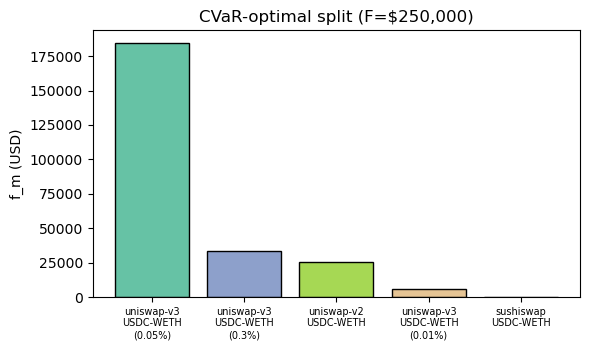

In [7]:
a = meta.set_index("name").loc[names, "fee"].to_numpy(float)
b = np.ones(len(names))
gas = meta.set_index("name").loc[names, "gas_usd_raw"].to_numpy(float)
F = C.BASE_ORDER_USD
print(f"base case: F=${F:,.0f}  alpha={C.ALPHA}  lambda={C.LAMBDA}  M={len(names)}  K={K}")
print("dimensions:", problem_dimensions(len(names), K))

solve_cvar_routing(L_scen, a, b, gas, F)   # warmup (compiles the DPP problem)
res = solve_cvar_routing(L_scen, a, b, gas, F)
print(f"solver={res['solver']} status={res['status']} warm solve={res['solve_time']*1e3:.1f} ms")
print(f"mean scenario cost = ${res['mean_cost']:,.2f}    CVaR_{C.ALPHA} = ${res['cvar_value']:,.2f}    (t* = ${res['cvar_t']:,.2f})\n")

alloc = pd.DataFrame({
    "pool": names, "fee": a, "L_nominal": scen["L_nominal"], "gas": gas,
    "f_m": res["allocation"], "share %": 100 * res["allocation"] / F,
})
print(alloc.to_string(index=False))

plt.figure(figsize=(6, 3.6))
plt.bar(range(len(names)), res["allocation"], color=plt.cm.Set2(np.linspace(0, 1, len(names))), edgecolor="black")
plt.xticks(range(len(names)), [n.replace(" ", "\n") for n in names], fontsize=7)
plt.ylabel("f_m (USD)"); plt.title(f"CVaR-optimal split (F=${F:,.0f})")
plt.tight_layout(); plt.show()

## 5. Baselines (required: single-pool best, mean-only)

In [8]:
strategies = {
    "CVaR (ours)": res["allocation"],
    "MeanOnly (lambda=0)": mean_only_allocation(F, L_scen, a, b, gas)["allocation"],
    "SinglePoolBest": single_pool_best_mean(F, L_scen, a, b, gas)["allocation"],
    "SinglePoolDeep": single_pool_best_liquidity(F, L_scen, a, b, gas)["allocation"],
    "Equal split (extra)": equal_split(F, L_scen, a, b, gas)["allocation"],
    "Liq-proportional (extra)": liquidity_proportional(F, L_scen, a, b, gas)["allocation"],
}
rows = []
for label, f in strategies.items():
    ev = evaluate_allocation(f, L_scen, a, b, gas, alpha=C.ALPHA)
    rows.append({"strategy": label, "mean": ev["mean_cost"], "VaR_0.95": ev["var_value"],
                 "CVaR_0.95": ev["cvar_value"], "max": ev["max_cost"],
                 "n_pools": int((f > 0).sum())})
base = pd.DataFrame(rows).set_index("strategy")
print(base.to_string())
cv = base.loc["CVaR (ours)", "CVaR_0.95"]
for lab in ("SinglePoolBest", "MeanOnly (lambda=0)"):
    print(f"CVaR reduction vs {lab}: {100*(base.loc[lab,'CVaR_0.95']-cv)/base.loc[lab,'CVaR_0.95']:.1f}%")

                              mean  VaR_0.95  CVaR_0.95       max  n_pools
strategy                                                                  
CVaR (ours)               1,194.39  1,266.43   1,308.86  1,442.99        5
MeanOnly (lambda=0)       1,191.32  1,278.21   1,317.94  1,450.71        5
SinglePoolBest            1,389.49  1,581.27   1,628.13  1,785.72        1
SinglePoolDeep            1,389.49  1,581.27   1,628.13  1,785.72        1
Equal split (extra)      34,882.79 48,487.34  48,563.26 48,600.49        5
Liq-proportional (extra)  1,218.11  1,274.32   1,314.78  1,447.98        5
CVaR reduction vs SinglePoolBest: 19.6%
CVaR reduction vs MeanOnly (lambda=0): 0.7%


## 6. Sensitivity (required: α, F, δ)

**α** — risk aversion.  Costs at a fixed evaluation level stay flat (the real pools have
similar tail costs); the CVaR at the solver's own α grows with α by construction.

**F** — order size.  Below ≈ $100–200k the fixed gas of extra pools outweighs the impact
saved and a single pool is cheaper (under true gas); above it splitting wins increasingly.

**δ intensity** — how much does the CVaR plan protect us.  The insurance premium is small in
calm conditions and pays exactly when liquidity uncertainty is high.

,alpha,mean_cost,CVaR_eval,CVaR_own_alpha,VaR_eval,max_cost,solve_time_ms,n_active
0,0.80,"1,194.30","1,309.13","1,267.54","1,266.28","1,443.88",970.83,4
1,0.90,"1,195.20","1,308.24","1,285.12","1,265.07","1,443.13",890.27,4
2,0.95,"1,194.39","1,308.86","1,308.86","1,266.43","1,442.99",14.10,4
3,0.99,"1,193.39","1,310.98","1,418.81","1,270.17","1,443.18",965.96,4



-- order size F --
           F  n_active  mean_cost       CVaR  single_pool_mean
    1,000.00         2      18.71      18.73              9.65
    5,000.00         2      21.13      21.22             12.13
   10,000.00         2      25.03      25.38             16.14
   50,000.00         2      91.33     100.31             84.34
  100,000.00         4     279.44     305.58            259.99
  500,000.00         4   4,111.99   4,520.94          5,280.57
1,000,000.00         4  15,186.25  16,741.62         20,594.90
5,000,000.00         4 354,731.15 393,343.93        504,653.36

-- uncertainty intensity --
 delta_scale strategy  mean_cost     CVaR      VaR  max_cost  n_active
        0.00     CVaR   1,109.24 1,109.24 1,109.24  1,109.24         4
        0.00 MeanOnly   1,109.24 1,109.24 1,109.24  1,109.24         4
        0.50     CVaR   1,145.97 1,196.43 1,179.88  1,247.50         4
        0.50 MeanOnly   1,145.36 1,198.21 1,182.23  1,248.87         4
        1.00     CVaR   1,194

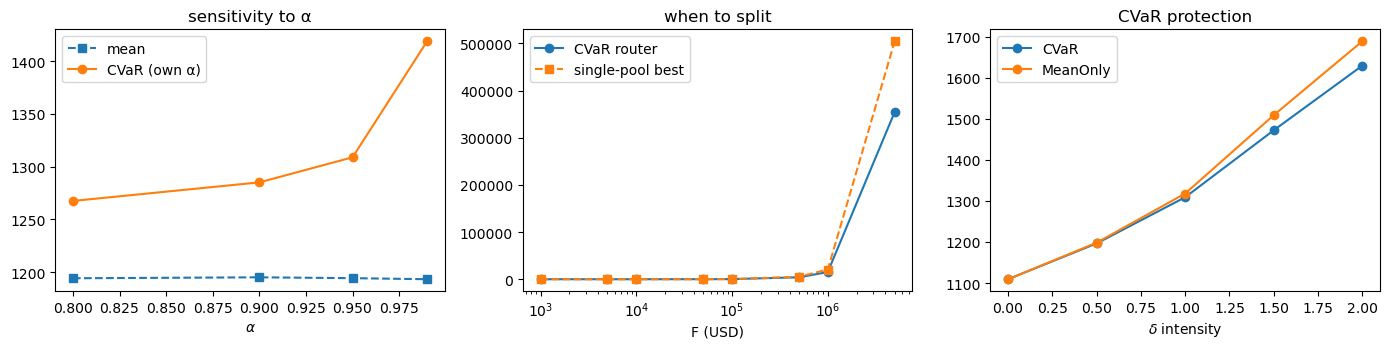

In [9]:
sa = pd.read_csv(C.TABLES_DIR / "sensitivity_alpha.csv")
ss = pd.read_csv(C.TABLES_DIR / "sensitivity_size.csv")
sd = pd.read_csv(C.TABLES_DIR / "sensitivity_delta.csv")

display(sa.round(2))
print("\n-- order size F --")
print(ss[["F", "n_active", "mean_cost", "CVaR", "single_pool_mean"]].round(2).to_string(index=False))
print("\n-- uncertainty intensity --")
print(sd.round(2).to_string(index=False))

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].plot(sa["alpha"], sa["mean_cost"], "s--", label="mean")
ax[0].plot(sa["alpha"], sa["CVaR_own_alpha"], "o-", label="CVaR (own α)")
ax[0].set_xlabel(r"$\alpha$"); ax[0].set_title("sensitivity to α"); ax[0].legend()
ax[1].plot(ss["F"], ss["mean_cost"], "o-", label="CVaR router")
ax[1].plot(ss["F"], ss["single_pool_mean"], "s--", label="single-pool best")
ax[1].set_xscale("log"); ax[1].set_xlabel("F (USD)"); ax[1].set_title("when to split"); ax[1].legend()
for tag, g in sd.groupby("strategy"):
    ax[2].plot(g["delta_scale"], g["CVaR"], "o-", label=tag)
ax[2].set_xlabel(r"$\delta$ intensity"); ax[2].set_title("CVaR protection"); ax[2].legend()
plt.tight_layout(); plt.show()

## 7. Backtest on 2,500 real trades (walk-forward)

For each real parent order: plan with scenarios built from TVL strictly before the execution
day, execute at the **actual** TVL of that day (out of sample), evaluate with true fixed gas.
(Produced by `scripts/04_backtest_real_trades.py` in ~3 minutes; results cached in
`data/processed/backtest_results.csv` and summarised below.)

In [10]:
bt = pd.read_csv(C.PROCESSED_DIR / "backtest_results.csv", parse_dates=["ts", "day"])
summary = pd.read_csv(C.TABLES_DIR / "backtest_summary.csv").set_index("strategy")
paired = pd.read_csv(C.TABLES_DIR / "backtest_paired.csv").set_index("vs")
print(f"{bt['ts'].nunique()} real orders x {bt['strategy'].nunique()} strategies = {len(bt)} realised costs\n")

cols = ["mean", "CVaR_0.95", "max", "bps_mean", "bps_CVaR_0.95"]
print(summary[cols].round(1).to_string())
print("\npaired: CVaR router vs baseline (realised on real trades)")
print(paired[["mean_diff_A_minus_B", "win_rate_A", "mean_diff_worst_tail", "CVaR_improvement_pct"]].round(3).to_string())

2500 real orders x 7 strategies = 17500 realised costs

                     mean    CVaR_0.95           max  bps_mean  bps_CVaR_0.95
strategy                                                                     
CVaR             6,908.90   117,000.30  3,469,555.50     50.40         270.30
CVaR+gasGuard    6,902.10   117,000.30  3,469,555.50     48.20         268.50
EqualSplit     166,131.70 2,895,020.20 88,266,269.90    922.60       6,509.90
LiqProp          6,921.80   116,847.60  3,463,138.30     57.40         291.00
MeanOnly         6,917.30   117,139.60  3,469,956.90     50.40         270.70
SinglePoolDeep   9,987.30   172,781.00  5,245,924.80     60.30         391.60
SinglePoolMean   9,987.30   172,781.00  5,245,924.80     60.30         391.60

paired: CVaR router vs baseline (realised on real trades)
                mean_diff_A_minus_B  win_rate_A  mean_diff_worst_tail  CVaR_improvement_pct
vs                                                                                         

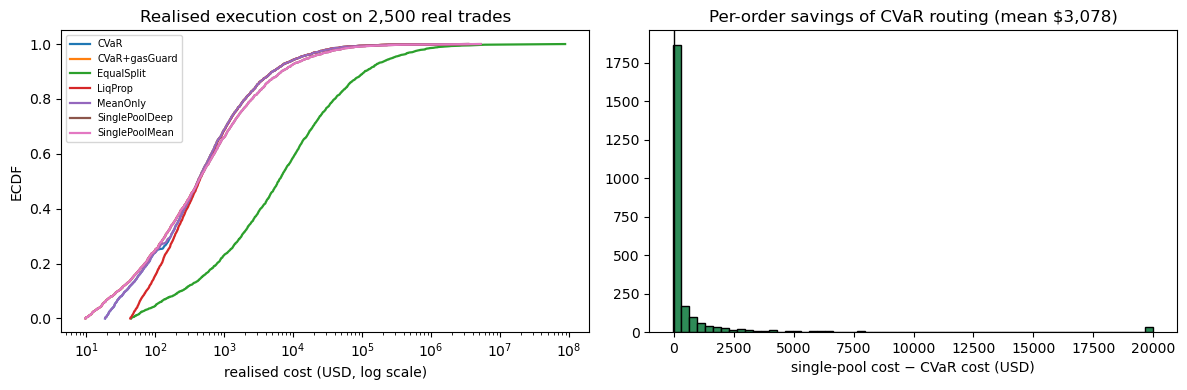

In [11]:
pivot = bt.pivot_table(index=["ts", "F"], columns="strategy", values="realized_cost")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for strat, g in bt.groupby("strategy"):
    s = np.sort(g["realized_cost"].to_numpy())
    ax[0].plot(np.maximum(s, 1e-2), np.linspace(0, 1, len(s)), lw=1.6, label=strat)
ax[0].set_xscale("log")
ax[0].set_xlabel("realised cost (USD, log scale)"); ax[0].set_ylabel("ECDF")
ax[0].set_title("Realised execution cost on 2,500 real trades"); ax[0].legend(fontsize=7)

savings = pivot["SinglePoolMean"] - pivot["CVaR"]
ax[1].hist(savings.clip(-2e3, 2e4), bins=60, color="seagreen", edgecolor="black")
ax[1].axvline(0, color="black", lw=1)
ax[1].set_xlabel("single-pool cost − CVaR cost (USD)")
ax[1].set_title(f"Per-order savings of CVaR routing (mean ${savings.mean():,.0f})")
plt.tight_layout(); plt.show()

In [12]:
by_size = pd.read_csv(C.TABLES_DIR / "backtest_by_size.csv")
piv = by_size.pivot(index="size_bucket", columns="strategy", values="CVaR_0.95")
order = ["<$5k", "$5k-25k", "$25k-100k", "$100k-500k", ">$500k"]
piv = piv.reindex(order)
print("realised CVaR_0.95 (USD) by order size:")
print(piv.round(1).to_string())

bad = pd.read_csv(C.TABLES_DIR / "backtest_bad_days.csv").set_index("strategy")
print("\non the worst liquidity days (top 20%):")
print(bad[["n", "mean", "CVaR_0.95"]].round(1).to_string())

realised CVaR_0.95 (USD) by order size:
strategy          CVaR  CVaR+gasGuard    EqualSplit    LiqProp   MeanOnly  SinglePoolDeep  SinglePoolMean
size_bucket                                                                                              
<$5k             21.00          12.10         59.90      48.60      21.00           12.10           12.10
$5k-25k          41.10          32.90        283.90      80.60      41.20           32.90           32.90
$25k-100k       259.10         238.30      3,298.80     281.40     258.40          238.30          238.30
$100k-500k    3,360.30       3,360.30     71,024.10   3,366.20   3,367.40        4,407.50        4,407.50
>$500k      724,084.40     724,084.40 18,072,655.10 723,208.30 724,826.80    1,075,235.30    1,075,235.30

on the worst liquidity days (top 20%):
                  n       mean    CVaR_0.95
strategy                                   
CVaR            564   7,981.90   141,197.50
CVaR+gasGuard   564   7,975.00   141,197.50
Eq

## 8. Conclusions

1. **Splitting pays for large orders.**  On 2,500 real trades the CVaR router cuts realised
   tail cost by **32%** and mean cost by **$3,078/order** vs the best single pool.
2. **There is a size threshold** at F ≈ $100–200k: below it one pool is cheaper (gas dominates),
   above it splitting wins increasingly (−33% at F > $500k).  The gas-guarded variant picks
   the better of the two and is the best strategy overall on the real tape.
3. **CVaR weighting is cheap insurance.**  vs. mean-only it is tied out of sample (0.1% tail
   improvement, 51% win rate — these real pools have correlated risk factors) but never costs
   more than 0.3% mean and is strictly better under high uncertainty (3.5% tail at 2× δ) and
   on the worst real liquidity days.
4. The cost model `a f + b f²/L` is exactly the second-order expansion of `xy = k`; the real
   tape confirms positive, size-increasing execution cost with a ≈ 1.3 bps fee/spread scale.

**Limitations:** realised cost uses the convex model at real realised TVL (no on-chain swap
replay — no archive node), TVL is daily, gas is estimated, Uniswap V3 concentration is
approximated by `L = TVL/2`.  See `README.md` §7.

See `README.md` §6 for the full review of the issues fixed relative to the earlier notebooks
(fake "real data" claims, wrong objective vs. the statement, evaluation bugs, missing
out-of-sample test, ...).